In [2]:
import numpy as np

def generate_stimulus_bank(
    field_size_deg=20.0,   # total width, so ±10 deg
    n_pix=128,
    orientations_deg=(0, 45, 90, 135),
    spatial_freqs_cpd=(0.5, 1.0, 2.0),
    phases_rad=(0.0, np.pi/2),
    envelope_center=(0.0, 0.0),
    envelope_sigma=(6.0, 6.0),
    beta=0.0,
    beta_dir_deg=0.0
):
    """
    Generate a bank of half-rectified sinusoid × envelope stimuli.

    Returns:
        stimuli: np.ndarray of shape (K, n_pix, n_pix)
        params: list of dict with the parameters for each stimulus
    """
    # coordinate grid in degrees
    half = field_size_deg / 2
    xs = np.linspace(-half, half, n_pix)
    ys = np.linspace(-half, half, n_pix)
    X, Y = np.meshgrid(xs, ys)

    x0, y0 = envelope_center
    sig_x, sig_y = envelope_sigma

    # base Gaussian envelope
    envelope = np.exp(-(((X - x0)**2) / (2 * sig_x**2) +
                        ((Y - y0)**2) / (2 * sig_y**2)))

    # optional exponential gradient
    gamma = np.deg2rad(beta_dir_deg)
    grad = np.exp(beta * (X * np.cos(gamma) + Y * np.sin(gamma)))

    env_total = envelope * grad

    stimuli = []
    params = []

    for psi_deg in orientations_deg:
        psi = np.deg2rad(psi_deg)
        # coordinate along orientation
        Xproj = X * np.cos(psi) + Y * np.sin(psi)

        for omega in spatial_freqs_cpd:
            for phi in phases_rad:
                # sinusoidal carrier
                carrier = np.sin(2 * np.pi * omega * Xproj + phi)

                # half-wave rectified
                carrier_rect = np.maximum(0, carrier)

                stim = carrier_rect * env_total

                stimuli.append(stim.astype(np.float32))
                params.append(dict(
                    orientation_deg=psi_deg,
                    spatial_freq_cpd=omega,
                    phase_rad=float(phi),
                    envelope_center=envelope_center,
                    envelope_sigma=envelope_sigma,
                    beta=beta,
                    beta_dir_deg=beta_dir_deg,
                ))

    stimuli = np.stack(stimuli, axis=0)  # (K, H, W)
    return stimuli, params

In [3]:
stim, params = generate_stimulus_bank()

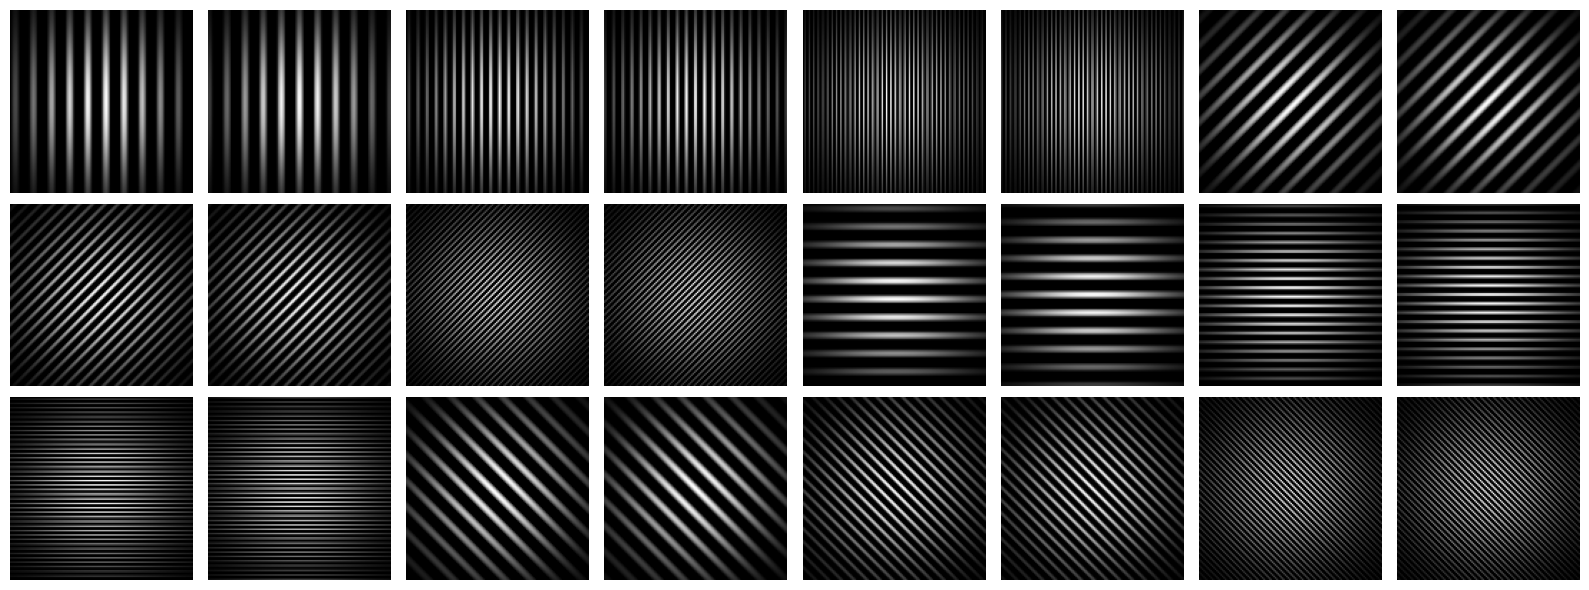

In [5]:
# Show all generated stimuli
import matplotlib.pyplot as plt
n_stim = stim.shape[0]
n_cols = 8
n_rows = int(np.ceil(n_stim / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 2, n_rows * 2))
for i in range(n_stim):
    ax = axes[i // n_cols, i % n_cols]
    ax.imshow(stim[i], cmap='gray', vmin=0, vmax=np.max(stim))
    ax.axis('off')
plt.tight_layout()
plt.show()